# Can LoFTR find more real matches? (input size and coarse threshold)

The fine stage needs inliers: the new map gives LoFTR about half the inliers of the old one, and many right places end with too few to be answered. Lowering the answer bar to 3 is **not** the fix (a bar that low depends on luck); the fix is to make the matcher see more **real** matches.

Two things limit LoFTR here:

* **Input size.** The canvas and the map window are 224 x 224 px, and LoFTR matches on a coarse grid of 1/8 of the size: 28 x 28 = 784 cells at most. Enlarging both pictures before LoFTR (`upscale`) gives a finer grid (2.0 gives 56 x 56); the matches are mapped back to the 224 px frame, so everything after the matcher is unchanged.
* **Coarse threshold.** LoFTR keeps a coarse match only when its probability is above 0.2. A lower value lets weaker matches through.

More matches is only good if they are **real** ones. So every variant is measured twice: on the **right** places (inliers should rise) and on **wrong** places, the best-ranked wrong coarse peaks (inliers should stay low; if they rise too, the matcher just got noisier and the answer bar cannot use them). The number that decides: the share of photos where the best right candidate reaches the bar **and** the best wrong one stays under it.

Nothing in the pipeline is changed by this notebook. The photos are spread over the whole set (not only the first 100 used by `Stage_Evaluation`).

In [1]:
import os, sys, math, time, gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src")); os.chdir(ROOT)

# ------------------------------------------------------------------ settings
MAP = "new"                 # base map of the official photos (see src/header/map_source.py)
MAP_MARGIN_M = 2500         # metres of map around the photos: smaller than the pipeline default, to set up faster
N_PHOTOS = 500
N_CHECK = 40                # photos checked (spread over the whole set)
K_PEAKS = 25                # coarse peaks looked at per photo
N_WRONG = 8                 # the best-ranked WRONG peaks that are matched per photo (look-alike places, the dangerous ones)
UPSCALE_LIST = [1.0, 1.5, 2.0, 3.0]
THR_LIST = [0.2, 0.1, 0.05]
CONF_TIGHT = 0.3            # the pipeline's confidence cut; "loose" keeps every match LoFTR proposes at the threshold
RANSAC_PIXELS = 3.0
BARS = [8, 12]              # answer bars the result is read at (the pipeline uses 12; Stage_Evaluation 8)
FOUND_SIGMA = 4.0
SEED = 45
plt.rcParams["figure.dpi"] = 90

## 1 · Set up the pipeline pieces (coarse search only) and pick the candidates

In [2]:
from single_photo_pipeline import SinglePhotoPipeline
from header import settings
from image_processing.geometry import render_query
from image_processing.map_levels import level_for_height, map_piece
from train.coarse_methods.inputs import make_inputs
from semantic_rerank.dino_rerank import coarse_top
from fine_matching.loftr_matcher import loftr_matches, fit_matches, prepare_roma_canvas
from header.settings import CTX

pipeline = SinglePhotoPipeline("official", "fused", semantic_layer=False, k_peaks=K_PEAKS, m_fine=K_PEAKS, matcher="loftr_minima",
                               satellite=MAP, map_margin_m=MAP_MARGIN_M)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup %.0f s" % (time.time() - start))
test_set, camera, level_images, matcher = pipeline.test_set, pipeline.camera, pipeline.level_images, pipeline.matcher

order = np.linspace(0, len(test_set.items) - 1, N_CHECK).astype(int)
cases = []                       # one entry per photo: the picture, and the right and wrong candidates (position, role)
skipped = 0
for index in order:
    item = test_set.items[index]
    truth, sigma = test_set.truths[index], test_set.sigmas[index]
    level = level_for_height(item["rel_height"], camera)
    canvas, valid = render_query(item, camera, level)
    cv2.setRNGSeed(settings.SEED)
    inputs = make_inputs(canvas, valid, level, test_set.priors[index], pipeline.families, pipeline.names)
    peaks = coarse_top(pipeline.coarse_method(inputs), inputs["geometry"], K_PEAKS)
    del inputs
    errors = np.array([math.hypot(p[1] - truth[0], p[2] - truth[1]) / sigma if p[1] < 1e8 else 1e9 for p in peaks])
    right = [k for k in range(len(peaks)) if errors[k] <= FOUND_SIGMA]
    wrong = [k for k in range(len(peaks)) if errors[k] > FOUND_SIGMA and peaks[k, 1] < 1e8][:N_WRONG]
    if len(right) == 0:
        skipped += 1
        continue
    right = right[:3]
    picture, reliable = prepare_roma_canvas(canvas, valid)
    cases.append(dict(photo=int(index), height=item["rel_height"], level=level, sigma=sigma, truth=truth, picture=picture, reliable=reliable,
                      candidates=[dict(x=peaks[k, 1], y=peaks[k, 2], role="right", rank=k) for k in right] + [dict(x=peaks[k, 1], y=peaks[k, 2], role="wrong", rank=k) for k in wrong]))
    torch.cuda.empty_cache()
print("%d photos have a right place among the first %d coarse peaks and are used (%d photos have none: lost before the fine stage, nothing to measure)" % (len(cases), K_PEAKS, skipped))
print("candidates per photo: %.1f right + %.1f wrong" % (np.mean([sum(c["role"] == "right" for c in case["candidates"]) for case in cases]), np.mean([sum(c["role"] == "wrong" for c in case["candidates"]) for case in cases])))

level 3: 0.85 m/pixel, picture 8035 x 7710, map coverage 100%
level 4: 1.20 m/pixel, picture 5682 x 5452, map coverage 100%
level 5: 1.70 m/pixel, picture 4017 x 3855, map coverage 100%
level 6: 2.40 m/pixel, picture 2841 x 2726, map coverage 100%
level 7: 3.39 m/pixel, picture 2008 x 1927, map coverage 100%


map store ready, took 22 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


setup 38 s


34 photos have a right place among the first 25 coarse peaks and are used (6 photos have none: lost before the fine stage, nothing to measure)
candidates per photo: 1.0 right + 8.0 wrong


## 2 · Run LoFTR on every candidate, once per variant (input size x coarse threshold)

The raw matches (positions and confidence) are kept, so the confidence cut and the RANSAC distance can be changed afterwards without running the network again.

In [3]:
raw = {}
seconds = {}
model = matcher.loftr_model
base_thr = model.coarse_matching.thr
for upscale in UPSCALE_LIST:
    for thr in THR_LIST:
        matcher.upscale = upscale
        model.coarse_matching.thr = thr
        stored = {}
        start = time.time()
        pairs = 0
        for case in cases:
            for position, cand in enumerate(case["candidates"]):
                tile = map_piece(level_images, case["level"], cand["x"], cand["y"], CTX)
                stored[(case["photo"], position)] = loftr_matches(matcher, case["picture"], tile)
                pairs += 1
        if settings.DEVICE == "cuda":
            torch.cuda.synchronize()
        raw[(upscale, thr)] = stored
        seconds[(upscale, thr)] = (time.time() - start) / pairs
        print("upscale %.1f, threshold %.2f: %d pairs, %.3f s per pair, %.0f matches per pair" % (
            upscale, thr, pairs, seconds[(upscale, thr)], np.mean([len(v[2]) for v in stored.values()])))
matcher.upscale = 1.0
model.coarse_matching.thr = base_thr

upscale 1.0, threshold 0.20: 306 pairs, 0.042 s per pair, 8 matches per pair


upscale 1.0, threshold 0.10: 306 pairs, 0.042 s per pair, 16 matches per pair


upscale 1.0, threshold 0.05: 306 pairs, 0.042 s per pair, 31 matches per pair


upscale 1.5, threshold 0.20: 306 pairs, 0.085 s per pair, 4 matches per pair


upscale 1.5, threshold 0.10: 306 pairs, 0.085 s per pair, 9 matches per pair


upscale 1.5, threshold 0.05: 306 pairs, 0.086 s per pair, 18 matches per pair


... (2 outputs left out)

upscale 2.0, threshold 0.05: 306 pairs, 0.207 s per pair, 9 matches per pair


upscale 3.0, threshold 0.20: 306 pairs, 0.494 s per pair, 0 matches per pair


upscale 3.0, threshold 0.10: 306 pairs, 0.611 s per pair, 1 matches per pair


upscale 3.0, threshold 0.05: 306 pairs, 0.614 s per pair, 2 matches per pair


## 3 · Read every variant

For each variant and confidence cut (tight = 0.3, loose = keep everything above the threshold):

* **right: median inliers** and the share of photos whose best right candidate reaches the bar;
* **wrong: best inliers** (median and 95th percentile over photos) and the share of photos where a wrong candidate reaches the bar: a **false alarm**;
* **clean at bar**: best right reaches the bar and the best wrong stays under it. This is what the answer rule can use;
* **error after the shift** of the best right candidate, in sigma (the precision the matcher gives).

In [4]:
def fit_all(variant, conf_cut, px):
    """For one variant: inliers and corrected position error for every candidate, from the stored matches."""
    out = {}
    for case in cases:
        for position, cand in enumerate(case["candidates"]):
            pa, pb, conf = raw[variant][(case["photo"], position)]
            cv2.setRNGSeed(settings.SEED)
            result = fit_matches(pa, pb, conf, case["reliable"], case["level"], conf_cut, px)
            error_sigma = math.hypot(cand["x"] + result["shift"][0] - case["truth"][0], cand["y"] + result["shift"][1] - case["truth"][1]) / case["sigma"]
            out[(case["photo"], position)] = (result["n_inliers"], error_sigma)
    return out


def read_variant(variant, conf_cut, px=RANSAC_PIXELS):
    fits = fit_all(variant, conf_cut, px)
    best_right, best_wrong, error_of_best = [], [], []
    for case in cases:
        right = [(fits[(case["photo"], k)][0], fits[(case["photo"], k)][1]) for k, c in enumerate(case["candidates"]) if c["role"] == "right"]
        wrong = [fits[(case["photo"], k)][0] for k, c in enumerate(case["candidates"]) if c["role"] == "wrong"]
        top = max(right, key=lambda r: r[0])
        best_right.append(top[0]); error_of_best.append(top[1])
        best_wrong.append(max(wrong) if wrong else 0)
    best_right, best_wrong, error_of_best = np.array(best_right), np.array(best_wrong), np.array(error_of_best)
    row = {"upscale": variant[0], "threshold": variant[1], "confidence cut": conf_cut, "s per pair": seconds[variant],
           "right: median inliers": np.median(best_right), "right: 25th pct": np.percentile(best_right, 25),
           "wrong: median best": np.median(best_wrong), "wrong: 95th pct": np.percentile(best_wrong, 95),
           "median error after shift (sigma)": np.median(error_of_best[best_right >= 8]) if (best_right >= 8).any() else np.nan}
    for bar in BARS:
        row["right >= %d" % bar] = (best_right >= bar).mean()
        row["false alarm at %d" % bar] = (best_wrong >= bar).mean()
        row["clean at %d" % bar] = ((best_right >= bar) & (best_wrong < bar)).mean()
    return row


rows = []
for variant in raw:
    rows.append(read_variant(variant, CONF_TIGHT))
    rows.append(read_variant(variant, variant[1]))                      # loose: every match LoFTR proposes at this threshold
table = pd.DataFrame(rows)
baseline = table[(table["upscale"] == 1.0) & (table["threshold"] == 0.2) & (table["confidence cut"] == CONF_TIGHT)].iloc[0]
print("%d photos, %d candidates | baseline = upscale 1.0, threshold 0.2, confidence cut %.1f (what the pipeline does today)" % (
    len(cases), sum(len(c["candidates"]) for c in cases), CONF_TIGHT))
display(table.sort_values("clean at %d" % BARS[0], ascending=False).round(3).reset_index(drop=True))

34 photos, 306 candidates | baseline = upscale 1.0, threshold 0.2, confidence cut 0.3 (what the pipeline does today)


,upscale,threshold,confidence cut,s per pair,right: median inliers,right: 25th pct,wrong: median best,wrong: 95th pct,median error after shift (sigma),right >= 8,false alarm at 8,clean at 8,right >= 12,false alarm at 12,clean at 12
0,1.0,0.10,0.10,0.042,51.0,18.50,4.0,9.35,0.553,0.941,0.118,0.824,0.853,0.029,0.824
1,1.0,0.05,0.05,0.042,66.5,33.00,5.0,12.40,0.552,1.000,0.206,0.794,0.971,0.059,0.912
2,1.5,0.10,0.10,0.085,41.0,8.25,0.0,4.35,0.563,0.765,0.000,0.765,0.706,0.000,0.706
3,1.0,0.20,0.20,0.042,35.0,11.00,0.0,7.00,0.677,0.794,0.029,0.765,0.706,0.000,0.706
4,1.0,0.20,0.30,0.042,24.0,6.00,0.0,3.00,0.578,0.706,0.000,0.706,0.676,0.000,0.676
5,1.0,0.10,0.30,0.042,24.0,6.00,0.0,3.00,0.578,0.706,0.000,0.706,0.676,0.000,0.676
6,1.0,0.05,0.30,0.042,24.0,6.00,0.0,3.00,0.578,0.706,0.000,0.706,0.676,0.000,0.676
7,1.5,0.05,0.05,0.086,64.0,14.00,3.5,8.70,0.610,0.794,0.088,0.706,0.735,0.029,0.706
8,1.5,0.20,0.20,0.085,18.5,0.00,0.0,0.00,0.619,0.647,0.000,0.647,0.588,0.000,0.588
9,2.0,0.05,0.05,0.207,26.5,0.00,0.0,6.35,0.536,0.647,0.029,0.618,0.647,0.000,0.647


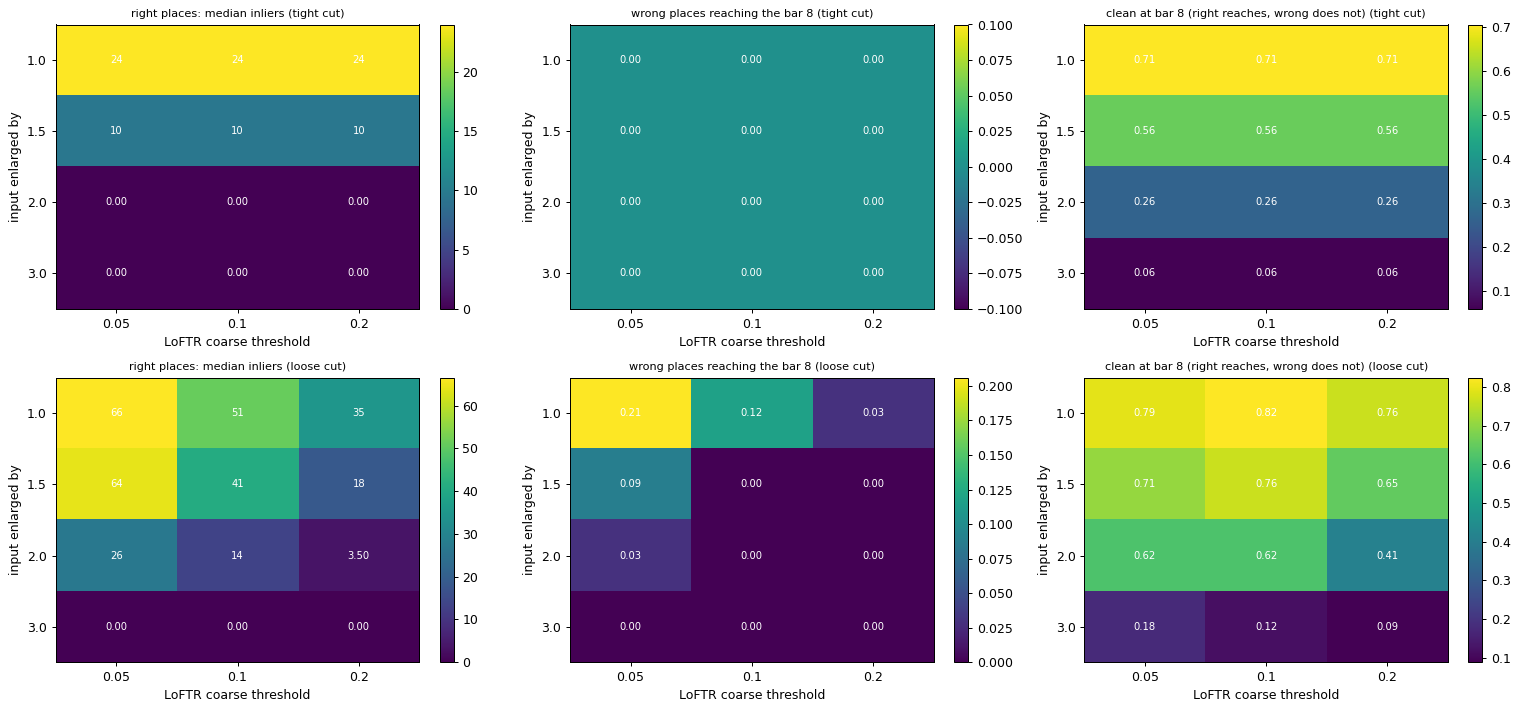

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for r, cut_name in enumerate(("tight", "loose")):
    part = table[(table["confidence cut"] == CONF_TIGHT)] if cut_name == "tight" else table[(table["confidence cut"] == table["threshold"]) & (table["threshold"] != CONF_TIGHT)]
    for axis, column, title in ((axes[r, 0], "right: median inliers", "right places: median inliers"), (axes[r, 1], "false alarm at %d" % BARS[0], "wrong places reaching the bar %d" % BARS[0]),
                                (axes[r, 2], "clean at %d" % BARS[0], "clean at bar %d (right reaches, wrong does not)" % BARS[0])):
        grid = part.pivot_table(index="upscale", columns="threshold", values=column)
        image = axis.imshow(grid.values, cmap="viridis", aspect="auto")
        axis.set_xticks(range(len(grid.columns))); axis.set_xticklabels(grid.columns)
        axis.set_yticks(range(len(grid.index))); axis.set_yticklabels(grid.index)
        axis.set_xlabel("LoFTR coarse threshold"); axis.set_ylabel("input enlarged by")
        axis.set_title("%s (%s cut)" % (title, cut_name), fontsize=9)
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                axis.text(j, i, "%.2f" % grid.values[i, j] if grid.values[i, j] < 5 else "%.0f" % grid.values[i, j], ha="center", va="center", color="white", fontsize=8)
        plt.colorbar(image, ax=axis, fraction=0.046)
plt.tight_layout()
plt.show()

## 4 · The best variant against the baseline: inliers of right and of wrong places

best variant by 'clean at 8': upscale 1.0, threshold 0.10, confidence cut 0.10


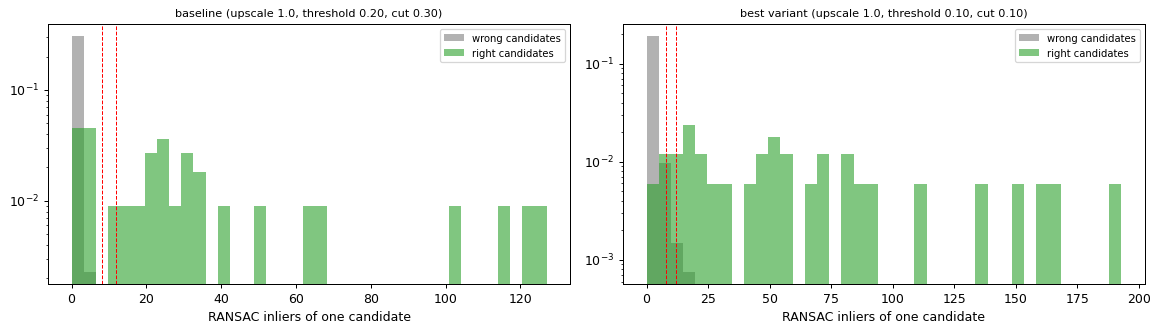

In [6]:
pick = table.sort_values(["clean at %d" % BARS[0], "false alarm at %d" % BARS[0]], ascending=[False, True]).iloc[0]
best_variant = (pick["upscale"], pick["threshold"])
best_cut = pick["confidence cut"]
print("best variant by 'clean at %d': upscale %.1f, threshold %.2f, confidence cut %.2f" % (BARS[0], best_variant[0], best_variant[1], best_cut))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for axis, (variant, cut, name) in zip(axes, [((1.0, 0.2), CONF_TIGHT, "baseline"), (best_variant, best_cut, "best variant")]):
    fits = fit_all(variant, cut, RANSAC_PIXELS)
    right_values = [fits[(c["photo"], k)][0] for c in cases for k, cand in enumerate(c["candidates"]) if cand["role"] == "right"]
    wrong_values = [fits[(c["photo"], k)][0] for c in cases for k, cand in enumerate(c["candidates"]) if cand["role"] == "wrong"]
    top = max(right_values + wrong_values + [10])
    bins = np.linspace(0, top, 40)
    axis.hist(wrong_values, bins=bins, alpha=0.6, color="tab:gray", label="wrong candidates", density=True)
    axis.hist(right_values, bins=bins, alpha=0.6, color="tab:green", label="right candidates", density=True)
    for bar in BARS:
        axis.axvline(bar, color="red", ls="--", lw=0.8)
    axis.set_yscale("log"); axis.set_xlabel("RANSAC inliers of one candidate"); axis.legend(fontsize=8)
    axis.set_title("%s (upscale %.1f, threshold %.2f, cut %.2f)" % (name, variant[0], variant[1], cut), fontsize=9)
plt.tight_layout()
plt.show()

## 5 · On the best variant: the confidence cut and the RANSAC distance (from the stored matches)

In [7]:
rows = []
for cut in sorted(set([best_variant[1], 0.2, 0.3, 0.4, 0.5, 0.6]) ):
    if cut < best_variant[1]:
        continue
    for px in (1.5, 2.0, 3.0, 4.0, 6.0):
        row = read_variant(best_variant, cut, px)
        row["ransac px"] = px
        rows.append(row)
sweep = pd.DataFrame(rows)
print("best variant (upscale %.1f, threshold %.2f): confidence cut x RANSAC distance, read at bar %d" % (best_variant[0], best_variant[1], BARS[0]))
display(sweep.pivot_table(index="confidence cut", columns="ransac px", values="clean at %d" % BARS[0]).round(3))
print("... and the share of photos where a WRONG place reaches the bar (false alarm):")
display(sweep.pivot_table(index="confidence cut", columns="ransac px", values="false alarm at %d" % BARS[0]).round(3))
out_dir = ROOT / "tests" / "Test_Iteration_2" / "results" / "loftr_more_matches"
out_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(out_dir / "variants.csv", index=False)
sweep.to_csv(out_dir / "best_variant_conf_ransac.csv", index=False)
print("saved in", out_dir)

best variant (upscale 1.0, threshold 0.10): confidence cut x RANSAC distance, read at bar 8


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.1,0.824,0.824,0.824,0.853,0.882
0.2,0.735,0.735,0.765,0.735,0.765
0.3,0.676,0.676,0.706,0.706,0.706
0.4,0.618,0.647,0.676,0.706,0.706
0.5,0.529,0.647,0.647,0.647,0.647
0.6,0.294,0.382,0.441,0.441,0.441


... and the share of photos where a WRONG place reaches the bar (false alarm):


ransac px,1.5,2.0,3.0,4.0,6.0
confidence cut,,,,,
0.1,0.059,0.088,0.118,0.118,0.088
0.2,0.029,0.029,0.029,0.059,0.029
0.3,0.000,0.000,0.000,0.000,0.000
0.4,0.000,0.000,0.000,0.000,0.000
0.5,0.000,0.000,0.000,0.000,0.000
0.6,0.000,0.000,0.000,0.000,0.000


saved in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Test_Iteration_2/results/loftr_more_matches
